## Case Study Application – Axiom Insider Trading case

Testing pipeline against a known case of insider trading fraud on polymarket seen in Feb 2026.

Market question : "Will Axiom be accused of insider trading?"

In [51]:
import requests, time
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
MARKET = "0x804bc34275d7d610dea3293c06105e925ebfcd6e454813aa27d59a882d50e86d"
YES_TOKEN = "103085646832854751469717081566514513444624814137586278494175134470235906780198"
TRADES_URL = "https://data-api.polymarket.com/v2/trades"
CSV_PATH = CSV_PATH = Path("analysis/data/axiom_trades.csv")

### Data Backfill

In [13]:
def fetch_all_trades(market: str, max_pages: int = 500) -> list[dict]:
    cursor = None 
    all_rows = []

    for page in range(max_pages): 
        params = {"condition": market, "limit": 1000} 
        if cursor is not None: 
            params['cursor'] = cursor

        r = requests.get(TRADES_URL, params=params, timeout=30)

        # If hit rate limit, wait & retry 
        if r.status_code == 429:              
            wait = float(r.headers.get("Retry-After", 5)) # Fallback to 5s if header is missing
            time.sleep(wait)
            continue  

        # Fetch data
        r.raise_for_status()
        body = r.json()
        rows = body['data']
        all_rows.extend(rows)
        print(f"page {page}: +{len(rows)} rows (total {len(all_rows)})")

        # Move to next page (if there is still)
        cursor = body["pagination"]["next_cursor"]
        if cursor is None: 
            break

        time.sleep(0.2)  

    return all_rows     

In [14]:
if CSV_PATH.exists(): 
    df = pd.read_csv(CSV_PATH, dtype={"token_id": str})
else: 
    rows = fetch_all_trades(market=MARKET)
    df = pd.DataFrame(rows)
    CSV_PATH.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(CSV_PATH, index=False)

print(len(df), "trades in total")
print((df["token_id"] == YES_TOKEN).sum(), "trades on the YES token")

page 0: +1000 rows (total 1000)
page 1: +1000 rows (total 2000)
page 2: +1000 rows (total 3000)
page 3: +1000 rows (total 4000)
page 4: +1000 rows (total 5000)
page 5: +1000 rows (total 6000)
page 6: +1000 rows (total 7000)
page 7: +1000 rows (total 8000)
page 8: +1000 rows (total 9000)
page 9: +1000 rows (total 10000)
page 10: +1000 rows (total 11000)
page 11: +1000 rows (total 12000)
page 12: +556 rows (total 12556)
12556 trades in total
5920 trades on the YES token


### Data preprocessing

In [58]:
# Keeping only the "YES" bets
yes_rows = df[df["token_id"] == YES_TOKEN]
yes_df = yes_rows.copy()

In [59]:
yes_df["timestamp"] = pd.to_datetime(yes_df["timestamp"], unit="s", utc=True)
yes_df["usdc"] = yes_df["size"] * yes_df["price"]
yes_df = yes_df.sort_values('timestamp', ascending=True).reset_index(drop=True)

In [60]:
yes_df.head(2)

,proxy_wallet,side,token_id,condition_id,size,price,timestamp,title,slug,icon,event_slug,outcome,outcome_index,name,pseudonym,bio,profile_image,profile_image_optimized,transaction_hash,usdc
0,0x6e1948bedd78472f21c4299ec3fcf7d9b159d630,BUY,1030856468328547514697170815665145134446248141...,0x804bc34275d7d610dea3293c06105e925ebfcd6e4548...,1.0989,0.91,2026-02-23 17:46:42+00:00,Will Axiom be accused of insider trading?,will-axiom-be-accused-of-insider-trading,https://polymarket-upload.s3.us-east-2.amazona...,which-crypto-company-will-zachxbt-expose-for-i...,Yes,0,vili4,Careful-Duty,,,,0x1d491af00feef48de83c23ed8da98a0f9d303f50d3cc...,0.999999
1,0x89cd944aa9cf528142e3557099c6992eb7ce4d7d,BUY,1030856468328547514697170815665145134446248141...,0x804bc34275d7d610dea3293c06105e925ebfcd6e4548...,10.0000,0.10,2026-02-23 17:57:56+00:00,Will Axiom be accused of insider trading?,will-axiom-be-accused-of-insider-trading,https://polymarket-upload.s3.us-east-2.amazona...,which-crypto-company-will-zachxbt-expose-for-i...,Yes,0,,,,,,0xbcf930b27376f3c1dd03d45ba83547d8fd74836882ba...,1.000000


### EDA

In [61]:
print(f"""
    First trade: {yes_df['timestamp'].min()}
    Last trade: {yes_df['timestamp'].max()}
    Distinct wallets: {yes_df['proxy_wallet'].nunique()}
    Total usdc traded: $ {yes_df['usdc'].sum():.{2}f}
    Nb of SELL: {len(yes_df[yes_df['side'] == 'SELL'])}
    Nb of BUY: {len(yes_df[yes_df['side'] == 'BUY'])}
    Median trade size: $ {yes_df['usdc'].median():.{2}f}
    Largest trade: $ {yes_df['usdc'].max():.{2}f}
""")


    First trade: 2026-02-23 17:46:42+00:00
    Last trade: 2026-02-26 16:12:08+00:00
    Distinct wallets: 1820
    Total usdc traded: $ 2634969.82
    Nb of SELL: 2637
    Nb of BUY: 3283
    Median trade size: $ 10.00
    Largest trade: $ 199791.56



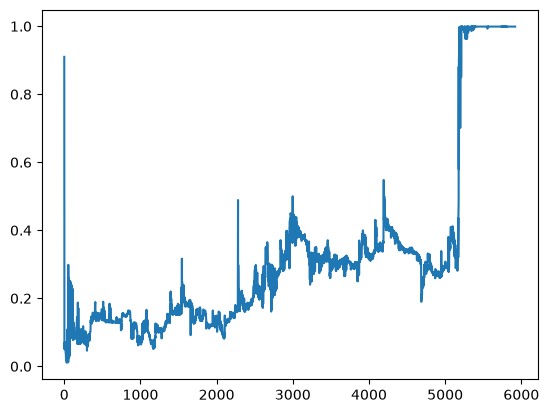

In [63]:
plt.plot(yes_df['price'])
plt.show()

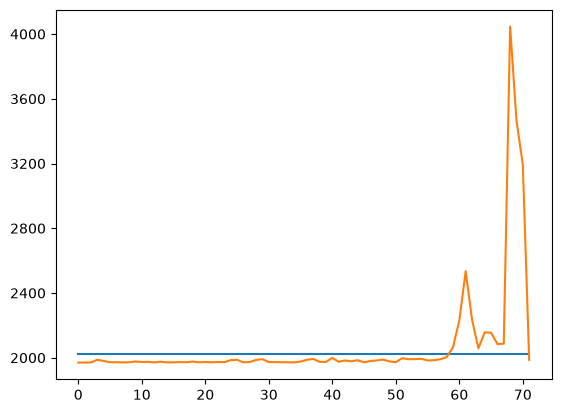

In [65]:
hourly_df = (
    yes_df.set_index('timestamp')
    .resample('1h')['usdc']
    .sum()
    .reset_index()
)

plt.plot(hourly_df)
plt.show()

In [ ]:
# Flagging the reveal (time when price did not go below 0.9 anymore)
yes_df["future_min"]
price_series = pd.series(yes_df['timestamp'], yes_df['price'])
price_series = price_series[::-1]
price_series['future_min'] = price_series.cummin()
price_series = price_series[::-1]